# New RLSK layer (R × LS × K) at 5′
This notebook multiplies the new RUSLE base factors into an **RLSK layer** on the 5′ UHTH grid. It then compares the result with the current product, `data/soil_erosion/rlsk_2012.tif` (GloSEM v1.1 R × LS × K, 25 km).

| Factor | Layer | Native grid |
|---|---|---|
| R | Sum of the 12 GloREDa monthly rasters (`R_Creation.ipynb`) | 30″, EPSG:4326 |
| K | **K RUSLE2** (main), K EPIC (`K_LS_Creation.ipynb`); both clipped at 0 | 1 km, Homolosine (ESRI:54052) |
| LS | **LS1** Desmet & Govers (main), LS2, GloSEM-compatible (`K_LS_Creation.ipynb`) | 5′ (mean of 3″ pixels) |

**Resolution.** LS exists only at 5′; the 90 m LS was never stored. So the finest RLSK is 5′. To keep as much detail as possible, **R × K is multiplied at 30″** and averaged to 5′. Only LS enters as a 5′ mean.

**Variants.** Every K is combined with every LS (6 layers). K EPIC corrected (Yang et al. 2024 Eq. 27) is not used: it is negative for K < 0.0267, which is 26% of pixels. The LS2 mosaic covers only box `n30e000` so far, so its variants are partial and are compared on their own cells. After `python RUSLE/scripts/run_ls_global.py --variants ls2`, rerunning this notebook makes them global.

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
from rasterio.vrt import WarpedVRT
from rasterio.warp import reproject, Resampling
from rasterio.windows import Window
from rasterio.features import rasterize

import sbtn_leaf.map_plotting as mp

OUT = Path("../../RUSLE/outputs")
R_FP = Path("../../RUSLE/notebooks/Rfactor_Annual.tif")
R_25KM_FP = Path("../../RUSLE/notebooks/Rfactor_Annual_25km.tif")           # from R_Creation.ipynb
TEMPLATE_FP = Path("../../data/soil_weather/uhth_thermal_climates.tif")     # UHTH 5' grid
RLSK_OLD_FP = Path("../../data/soil_erosion/rlsk_2012.tif")
GLOSEM = Path("../../data/soil_erosion/GloSEM_v1.1")
GLOSEM_FPS = {f: GLOSEM / f"RUSLE_{f}Factor_v1.1_25km.tif" for f in ("R", "K", "LS")}
COUNTRIES_FP = Path("../../data/world_maps/high_res/ne_10m_admin_0_countries.shp")

# name -> (code, 1 km raster, 25 km mean from K_LS_Creation.ipynb)
K_VARIANTS = {
    "K RUSLE2": ("krusle2", OUT / "k_rusle2.tif", OUT / "k_rusle2_25km.tif"),
    "K EPIC": ("kepic", OUT / "k_epic.tif", OUT / "k_epic_25km.tif"),
}
# name -> (code, 5' mosaic)
LS_VARIANTS = {
    "LS1": ("ls1", OUT / "rusle_LS_all_5m.tif"),
    "LS2": ("ls2", OUT / "rusle_LS_all_5m_ls2.tif"),
    "LS GloSEM-compatible": ("lsglosem", OUT / "rusle_LS_all_5m_glosem_compat.tif"),
}
MAIN = ("K RUSLE2", "LS1")
VARIANTS = [(k, ls) for k in K_VARIANTS for ls in LS_VARIANTS]


def vname(k, ls):
    return f"{k} × {ls}"


def rk_30s_fp(k):
    return OUT / f"rusle_RK_30s_{K_VARIANTS[k][0]}.tif"


def rlsk_fp(k, ls):
    if (k, ls) == MAIN:
        return OUT / "rusle_RLSK_5m.tif"
    return OUT / f"rusle_RLSK_5m_{K_VARIANTS[k][0]}_{LS_VARIANTS[ls][0]}.tif"


RLSK_LABEL = "RLSK (t ha$^{-1}$ yr$^{-1}$ per unit C·P)"

Could not determine dtype for column 1, falling back to string


In [2]:
for fp in [R_FP, *(v[1] for v in K_VARIANTS.values()), *(v[1] for v in LS_VARIANTS.values()), RLSK_OLD_FP, TEMPLATE_FP]:
    with rasterio.open(fp) as s:
        print(f"{fp.name:42s} {s.width:>6} x {s.height:<6} res {s.res[0]:.6g}  {s.crs}  {s.dtypes[0]}  nodata {s.nodata}")

Rfactor_Annual.tif                          43200 x 17924  res 0.00833333  EPSG:4326  int32  nodata -32768.0
k_rusle2.tif                                39812 x 14509  res 1000  ESRI:54052  float32  nodata nan


k_epic.tif                                  39812 x 14509  res 1000  ESRI:54052  float32  nodata nan
rusle_LS_all_5m.tif                          4320 x 2160   res 0.0833333  EPSG:4326  float32  nodata nan
rusle_LS_all_5m_ls2.tif                      4320 x 2160   res 0.0833333  EPSG:4326  float32  nodata nan
rusle_LS_all_5m_glosem_compat.tif            4320 x 2160   res 0.0833333  EPSG:4326  float32  nodata nan
rlsk_2012.tif                                1728 x 673    res 0.208333  EPSG:4326  float64  nodata -1.7976931348623157e+308
uhth_thermal_climates.tif                    4320 x 2083   res 0.0833333  EPSG:4326  uint8  nodata 0.0


## 1. R × K at 30″
Each strip of R rows is read on R's native 30″ grid. K is read through a `WarpedVRT` onto exactly the same strip; K at 1 km and R at 30″ are about the same size, so bilinear resampling is enough. Pixels missing in either layer are NaN. Nothing global at 30″ is held in memory.

The 30″ products (`rusle_RK_30s_<k>.tif`, about 0.6 GB each) are reused if they are newer than their R and K inputs. They can be deleted after section 2.

In [3]:
STRIP = 1024   # rows per strip (multiple of the 512 px tile size)


def build_rk_30s(k_fp, out_fp, strip=STRIP):
    with rasterio.open(R_FP) as r, rasterio.open(k_fp) as k:
        profile = r.profile.copy()
        profile.update(dtype="float32", nodata=np.nan, compress="deflate", predictor=3, tiled=True,
                       blockxsize=512, blockysize=512, BIGTIFF="YES")
        with WarpedVRT(k, crs=r.crs, transform=r.transform, width=r.width, height=r.height,
                       resampling=Resampling.bilinear, src_nodata=np.nan, nodata=np.nan,
                       dtype="float32", warp_mem_limit=1024) as kv, \
             rasterio.open(out_fp, "w", **profile) as dst:
            for row0 in range(0, r.height, strip):
                win = Window(0, row0, r.width, min(strip, r.height - row0))
                rv = r.read(1, window=win)
                kk = kv.read(1, window=win)
                ok = (rv != r.nodata) & np.isfinite(kk)
                dst.write(np.where(ok, rv.astype(np.float32) * kk, np.nan).astype(np.float32), 1, window=win)


for k, (code_, k_fp, _) in K_VARIANTS.items():
    fp = rk_30s_fp(k)
    if fp.exists() and fp.stat().st_mtime > max(k_fp.stat().st_mtime, R_FP.stat().st_mtime):
        print(f"reusing {fp.name}")
        continue
    t0 = time.time()
    build_rk_30s(k_fp, fp)
    print(f"{fp.name}: {time.time() - t0:.0f} s, {fp.stat().st_size / 1e9:.2f} GB")

rusle_RK_30s_krusle2.tif: 450 s, 0.63 GB


rusle_RK_30s_kepic.tif: 465 s, 0.62 GB


## 2. Onto the 5′ UHTH grid
- **RK:** area mean of the 30″ RK onto the UHTH grid (`Resampling.average`; NaN pixels are ignored).
- **LS:** the LS mosaics are on the same 5′ lattice (anchored at −180°, 90°), but extend to 90°N. The UHTH grid stops at 83.58°N, so LS is cropped by a window. No resampling is needed.

In [4]:
with rasterio.open(TEMPLATE_FP) as t:
    T_TR, T_CRS, T_SHAPE = t.transform, t.crs, t.shape
    T_PROFILE = t.profile.copy()
T_PROFILE.update(dtype="float32", nodata=np.nan, compress="deflate", predictor=3)
T_LAT = T_TR.f + (np.arange(T_SHAPE[0]) + 0.5) * T_TR.e
T_W = np.broadcast_to(np.cos(np.radians(T_LAT))[:, None], T_SHAPE)          # cell-area weights


def to_template(src_fp, resampling=Resampling.average):
    dst = np.full(T_SHAPE, np.nan, dtype=np.float32)
    with rasterio.open(src_fp) as src:
        reproject(rasterio.band(src, 1), dst, src_nodata=src.nodata, dst_transform=T_TR, dst_crs=T_CRS,
                  dst_nodata=np.nan, resampling=resampling, warp_mem_limit=2048, num_threads=4)
    return dst


def ls_on_template(ls_fp):
    with rasterio.open(ls_fp) as s:
        row0 = round((T_TR.f - s.transform.f) / s.transform.e)
        tol = 1e-6 * s.transform.a                       # same lattice up to float rounding
        assert abs(s.transform.a - T_TR.a) < tol and abs(s.transform.c - T_TR.c) < tol
        assert abs(s.transform.f + row0 * s.transform.e - T_TR.f) < tol
        assert s.width == T_SHAPE[1]
        return s.read(1, window=Window(0, row0, s.width, T_SHAPE[0])).astype(np.float32)


rk5 = {}
for k in K_VARIANTS:
    t0 = time.time()
    rk5[k] = to_template(rk_30s_fp(k))
    print(f"RK 5' ({k}): {time.time() - t0:.0f} s, {np.isfinite(rk5[k]).sum():,} cells")

ls5 = {ls: ls_on_template(fp) for ls, (_, fp) in LS_VARIANTS.items()}
for ls, a in ls5.items():
    print(f"LS 5' ({ls}): {np.isfinite(a).sum():,} cells")

RK 5' (K RUSLE2): 21 s, 2,159,109 cells


RK 5' (K EPIC): 22 s, 2,159,109 cells


LS 5' (LS1): 2,301,347 cells
LS 5' (LS2): 85,902 cells
LS 5' (LS GloSEM-compatible): 2,301,347 cells


## 3. RLSK at 5′, all variants
$RLSK = \overline{R\cdot K}^{\,5'}\cdot \overline{LS}^{\,5'}$, NaN where either factor is missing. Statistics are area-weighted (cos latitude) over each layer's own valid cells.

In [5]:
def wmean(a, m, w=T_W):
    return float(np.average(a[m], weights=w[m])) if m.any() else np.nan


rlsk5 = {}
rows = {}
for k, ls in VARIANTS:
    a = rk5[k] * ls5[ls]
    rlsk5[(k, ls)] = a
    with rasterio.open(rlsk_fp(k, ls), "w", **T_PROFILE) as dst:
        dst.write(a.astype(np.float32), 1)
    m = np.isfinite(a)
    v = a[m]
    rows[vname(k, ls)] = {"file": rlsk_fp(k, ls).name, "cells": int(m.sum()),
                          "mean (area-w.)": wmean(a, m), "median": np.median(v),
                          "p95": np.percentile(v, 95), "p99": np.percentile(v, 99), "max": v.max()}
rlsk5_stats = pd.DataFrame(rows).T
display(rlsk5_stats)

# Coverage check (main variant): RLSK cells = intersection of the RK and LS masks
k, ls = MAIN
print(f"RK cells {np.isfinite(rk5[k]).sum():,} | LS cells {np.isfinite(ls5[ls]).sum():,} | "
      f"RLSK cells {np.isfinite(rlsk5[MAIN]).sum():,} | RK-only {(np.isfinite(rk5[k]) & ~np.isfinite(ls5[ls])).sum():,} | "
      f"LS-only {(~np.isfinite(rk5[k]) & np.isfinite(ls5[ls])).sum():,}")

,file,cells,mean (area-w.),median,p95,p99,max
K RUSLE2 × LS1,rusle_RLSK_5m.tif,2158073,318.604544,16.55057,1422.072754,4139.682617,26715.896484
K RUSLE2 × LS2,rusle_RLSK_5m_krusle2_ls2.tif,84294,92.393829,13.180788,454.697144,818.968689,2257.753662
K RUSLE2 × LS GloSEM-compatible,rusle_RLSK_5m_krusle2_lsglosem.tif,2158073,176.179778,10.522367,786.851868,2158.774902,13437.767578
K EPIC × LS1,rusle_RLSK_5m_kepic_ls1.tif,2158073,367.511299,18.305378,1619.203979,4865.290527,28520.275391
K EPIC × LS2,rusle_RLSK_5m_kepic_ls2.tif,84294,106.508899,14.648405,524.807678,918.350403,2669.431396
K EPIC × LS GloSEM-compatible,rusle_RLSK_5m_kepic_lsglosem.tif,2158073,203.297664,11.608618,894.177795,2556.786621,14345.348633


RK cells 2,159,109 | LS cells 2,301,347 | RLSK cells 2,158,073 | RK-only 1,036 | LS-only 143,274


Raster has 2,132,565 unique values. Min: 0.00. Max: 26,715.90
Using quantile edges


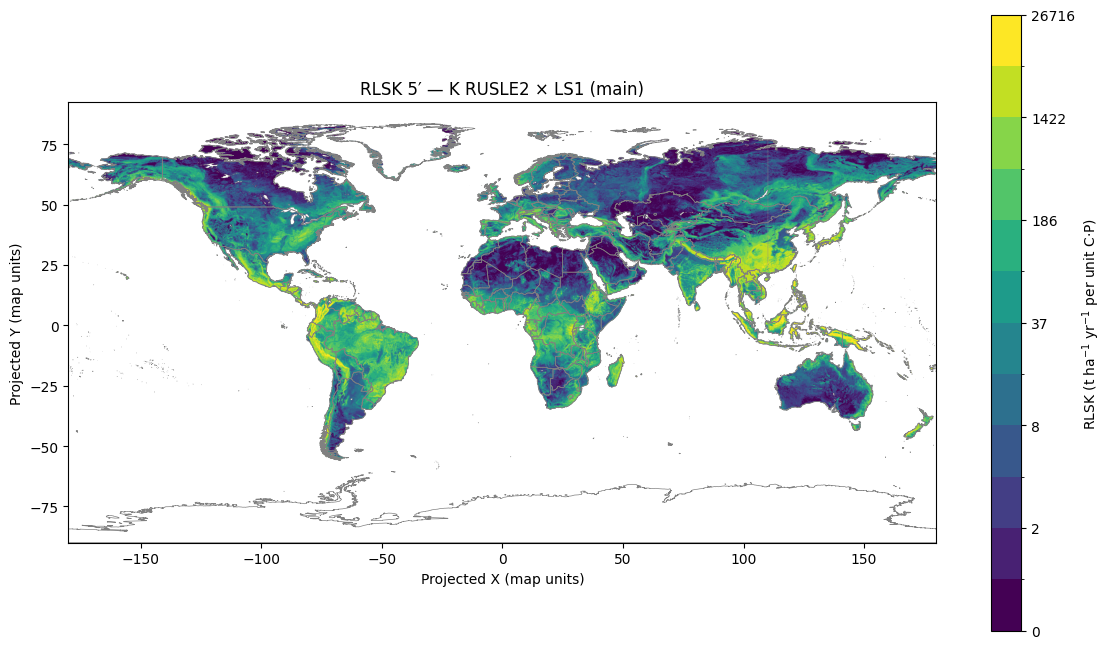

In [6]:
main_v = rlsk5[MAIN][np.isfinite(rlsk5[MAIN])]
RLSK_QUANT = [0] + [float(np.round(q, 1)) for q in np.percentile(main_v, [10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 99])] + [float(main_v.max())]

mp.plot_raster_on_world_extremes_cutoff(
    rlsk_fp(*MAIN), f"RLSK 5′ — {vname(*MAIN)} (main)", label_title=RLSK_LABEL,
    perc_cutoff=0, quantiles=RLSK_QUANT,
)

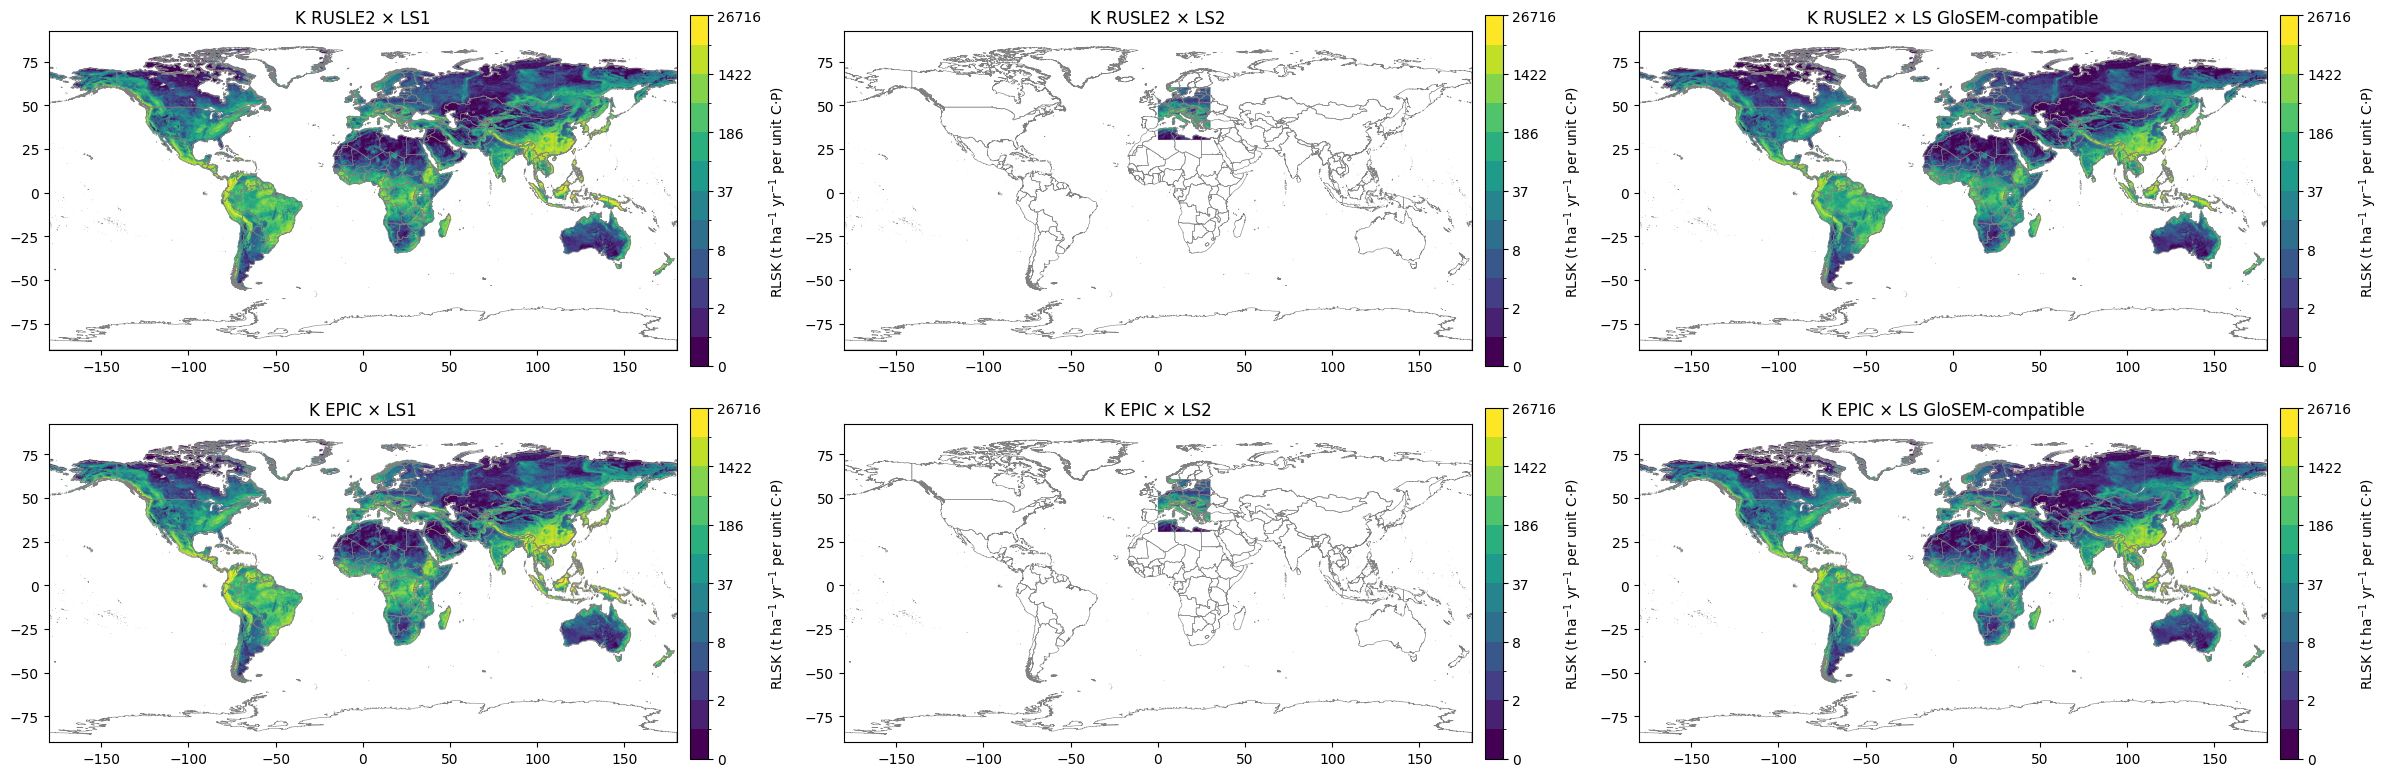

(<Figure size 2400x800 with 12 Axes>,
 array([[<Axes: title={'center': 'K RUSLE2 × LS1'}>,
         <Axes: title={'center': 'K RUSLE2 × LS2'}>,
         <Axes: title={'center': 'K RUSLE2 × LS GloSEM-compatible'}>],
        [<Axes: title={'center': 'K EPIC × LS1'}>,
         <Axes: title={'center': 'K EPIC × LS2'}>,
         <Axes: title={'center': 'K EPIC × LS GloSEM-compatible'}>]],
       dtype=object))

In [7]:
mp.plot_n_rasters_on_world_extremes_cutoff(
    [rlsk_fp(k, ls) for k, ls in VARIANTS],
    titles=[vname(k, ls) for k, ls in VARIANTS],
    label_title=RLSK_LABEL, perc_cutoff=0, quantiles=RLSK_QUANT,
    n_cols=3, x_size=8, y_size=4,
)

## 4. Does the 30″ R × K step matter?
For the main variant, R and K are also averaged to 5′ separately and multiplied with LS, $\overline{R}\cdot\overline{K}\cdot\overline{LS}$. The ratio to the main layer shows how much the covariance of R and K inside 5′ cells changes the result.

In [8]:
r5 = to_template(R_FP)
k5 = to_template(K_VARIANTS[MAIN[0]][1])
naive = r5 * k5 * ls5[MAIN[1]]
m = np.isfinite(naive) & np.isfinite(rlsk5[MAIN]) & (rlsk5[MAIN] > 0)
cell_ratio = naive[m] / rlsk5[MAIN][m]
display(pd.Series({
    "cells": int(m.sum()),
    "ratio of area-weighted means (separate / 30″ RK)": wmean(naive, m) / wmean(rlsk5[MAIN], m),
    "median cell ratio": np.median(cell_ratio),
    "p01 cell ratio": np.percentile(cell_ratio, 1),
    "p99 cell ratio": np.percentile(cell_ratio, 99),
    "cells differing by > 5 %": f"{100 * np.mean(np.abs(cell_ratio - 1) > 0.05):.2f} %",
}).to_frame("value"))
del r5, k5, naive

,value
cells,2152531
ratio of area-weighted means (separate / 30″ RK),0.999895
median cell ratio,1.000026
p01 cell ratio,0.952571
p99 cell ratio,1.055282
cells differing by > 5 %,2.07 %


## 5. Comparison with `rlsk_2012.tif` (GloSEM v1.1, 25 km)
### 5.1 Is `rlsk_2012` the product of the GloSEM v1.1 R, K and LS?
This must hold for the factor decomposition in 5.4 to be valid.

In [9]:
def read_25(fp):
    with rasterio.open(fp) as s:
        a = s.read(1).astype(np.float64)
        nd = s.nodata
    bad = ~np.isfinite(a) | (np.abs(a) > 1e30)
    if nd is not None and np.isfinite(nd):
        bad |= a == nd
    a[bad] = np.nan
    return a


with rasterio.open(RLSK_OLD_FP) as s:
    G_TR, G_CRS, G_SHAPE = s.transform, s.crs, s.shape
    G_PROFILE = s.profile.copy()
G_PROFILE.update(dtype="float32", nodata=-9999.0, compress="deflate")
G_LAT = G_TR.f + (np.arange(G_SHAPE[0]) + 0.5) * G_TR.e
G_W = np.broadcast_to(np.cos(np.radians(G_LAT))[:, None], G_SHAPE)

old = read_25(RLSK_OLD_FP)
g = {f: read_25(fp) for f, fp in GLOSEM_FPS.items()}
prod = g["R"] * g["K"] * g["LS"]
m = np.isfinite(old) & np.isfinite(prod) & (prod > 0)
rel = old[m] / prod[m]
display(pd.Series({
    "rlsk_2012 valid cells": int(np.isfinite(old).sum()),
    "cells with R, K, LS all valid": int(np.isfinite(prod).sum()),
    "median rlsk_2012 / (R·K·LS)": np.median(rel),
    "max |ratio − 1|": np.max(np.abs(rel - 1)),
}).to_frame("value"))

,value
rlsk_2012 valid cells,2.794210e+05
"cells with R, K, LS all valid",2.794210e+05
median rlsk_2012 / (R·K·LS),1.000000e+00
max |ratio − 1|,4.440892e-16


### 5.2 All variants on the 25 km grid
Each 5′ RLSK is area-averaged onto the GloSEM grid. Comparisons use the cells valid in both layers. Means are area-weighted. "Coverage" is the share of `rlsk_2012` land cells that the variant covers.

In [10]:
def to_glosem(arr):
    dst = np.full(G_SHAPE, np.nan, dtype=np.float64)
    reproject(arr.astype(np.float32), dst, src_transform=T_TR, src_crs=T_CRS, src_nodata=np.nan,
              dst_transform=G_TR, dst_crs=G_CRS, dst_nodata=np.nan, resampling=Resampling.average)
    return dst


def gwmean(a, m):
    return float(np.average(a[m], weights=G_W[m])) if m.any() else np.nan


new25 = {v: to_glosem(a) for v, a in rlsk5.items()}

RLSK_NEW_25KM_FP = OUT / "rusle_RLSK_5m_25km.tif"
RLSK_OLD_F32_FP = OUT / "rlsk_2012_f32.tif"     # float32 copy with nodata -9999 for the plotting helpers
for fp, a in [(RLSK_NEW_25KM_FP, new25[MAIN]), (RLSK_OLD_F32_FP, old)]:
    with rasterio.open(fp, "w", **G_PROFILE) as dst:
        dst.write(np.where(np.isfinite(a), a, -9999.0).astype(np.float32), 1)

old_ok = np.isfinite(old)
summary = {}
for (k, ls), a in new25.items():
    c = old_ok & np.isfinite(a)
    pos = c & (old > 0) & (a > 0)
    main_same = gwmean(new25[MAIN], c & np.isfinite(new25[MAIN])) / gwmean(old, c & np.isfinite(new25[MAIN]))
    summary[vname(k, ls)] = {
        "K": k, "LS": ls,
        "coverage %": 100 * c.sum() / old_ok.sum(),
        "mean rlsk_2012": gwmean(old, c),
        "mean new": gwmean(a, c),
        "new ÷ 2012 (means)": gwmean(a, c) / gwmean(old, c),
        "new ÷ 2012 (median cell)": np.median(a[pos] / old[pos]),
        "main ÷ 2012, same cells": main_same,
        "Pearson r": np.corrcoef(a[c], old[c])[0, 1],
        "Pearson r (log)": np.corrcoef(np.log(a[pos]), np.log(old[pos]))[0, 1],
        "Spearman": pd.Series(a[c]).corr(pd.Series(old[c]), method="spearman"),
    }
variant_summary = pd.DataFrame(summary).T
variant_summary.to_csv(OUT / "rlsk_variants_vs_2012.csv")

LS_CSS = {"LS1": "background-color:#c8e6c9; color:#000", "LS GloSEM-compatible": "background-color:#bbdefb; color:#000",
          "LS2": "background-color:#ffe0b2; color:#000"}
num_cols = [c for c in variant_summary.columns if c not in ("K", "LS")]
display(variant_summary.style
        .apply(lambda r: [LS_CSS[r["LS"]] + ("; font-weight:bold" if (r["K"], r["LS"]) == MAIN else "")] * len(r), axis=1)
        .format("{:.3f}", subset=num_cols, na_rep="—"))

,K,LS,coverage %,mean rlsk_2012,mean new,new ÷ 2012 (means),new ÷ 2012 (median cell),"main ÷ 2012, same cells",Pearson r,Pearson r (log),Spearman
K RUSLE2 × LS1,K RUSLE2,LS1,99.987,117.715,359.964,3.058,1.912,3.058,0.704,0.828,0.826
K RUSLE2 × LS2,K RUSLE2,LS2,3.788,49.958,107.354,2.149,2.265,3.214,0.729,0.841,0.836
K RUSLE2 × LS GloSEM-compatible,K RUSLE2,LS GloSEM-compatible,99.987,117.715,199.497,1.695,1.218,3.058,0.705,0.832,0.833
K EPIC × LS1,K EPIC,LS1,99.987,117.715,416.123,3.535,2.140,3.058,0.707,0.831,0.828
K EPIC × LS2,K EPIC,LS2,3.788,49.958,123.771,2.477,2.560,3.214,0.730,0.843,0.839
K EPIC × LS GloSEM-compatible,K EPIC,LS GloSEM-compatible,99.987,117.715,230.580,1.959,1.366,3.058,0.708,0.834,0.834


In [11]:
def describe(v):
    return {"n cells": v.size, "mean (unweighted)": v.mean(), "std": v.std(), "min": v.min(),
            "p05": np.percentile(v, 5), "median": np.median(v), "p95": np.percentile(v, 95), "max": v.max()}


a = new25[MAIN]
c = old_ok & np.isfinite(a)
display(pd.DataFrame({
    f"{vname(*MAIN)} (own valid cells)": describe(a[np.isfinite(a)]),
    "rlsk_2012 (own valid cells)": describe(old[old_ok]),
    f"{vname(*MAIN)} (common cells)": describe(a[c]),
    "rlsk_2012 (common cells)": describe(old[c]),
}).T.round(2))

,n cells,mean (unweighted),std,min,p05,median,p95,max
K RUSLE2 × LS1 (own valid cells),363315.0,270.19,804.59,0.0,0.60,19.68,1514.87,25533.90
rlsk_2012 (own valid cells),279421.0,96.62,294.15,0.0,1.15,14.52,455.20,10179.75
K RUSLE2 × LS1 (common cells),279385.0,287.77,795.63,0.0,0.90,28.40,1619.12,19701.77
rlsk_2012 (common cells),279385.0,96.60,294.06,0.0,1.15,14.52,455.16,10179.75


### 5.3 By continent
Continents come from Natural Earth, with Russia east of 60°E counted as Asia (as in `K_LS_Creation.ipynb`).

In [12]:
CONTINENTS = ["Africa", "Asia", "Europe", "North America", "Oceania", "South America"]
countries = gpd.read_file(COUNTRIES_FP).to_crs(G_CRS)
codes = {name: i + 1 for i, name in enumerate(CONTINENTS)}
continent = rasterize([(geom, codes[c]) for geom, c in zip(countries.geometry, countries["CONTINENT"]) if c in codes],
                      out_shape=G_SHAPE, transform=G_TR, fill=0, dtype="uint8")
g_lon = G_TR.c + (np.arange(G_SHAPE[1]) + 0.5) * G_TR.a
continent[(continent == codes["Europe"]) & (g_lon[None, :] > 60)] = codes["Asia"]

regions = {name: continent == code for name, code in codes.items()}
regions["World"] = np.ones(G_SHAPE, dtype=bool)

rows = []
for (k, ls), a in new25.items():
    for reg, in_reg in regions.items():
        c = in_reg & old_ok & np.isfinite(a)
        rows.append({"variant": vname(k, ls), "K": k, "LS": ls, "region": reg,
                     "coverage %": 100 * c.sum() / max((in_reg & old_ok).sum(), 1),
                     "mean rlsk_2012": gwmean(old, c), "mean new": gwmean(a, c),
                     "new ÷ 2012": gwmean(a, c) / gwmean(old, c) if c.any() else np.nan,
                     "Spearman": pd.Series(a[c]).corr(pd.Series(old[c]), method="spearman") if c.sum() > 10 else np.nan})
by_continent = pd.DataFrame(rows)
by_continent.to_csv(OUT / "rlsk_new_vs_2012_by_continent.csv", index=False)

main_tbl = by_continent[by_continent["variant"] == vname(*MAIN)].set_index("region").drop(columns=["variant", "K", "LS"])
display(main_tbl.round(2))
display(by_continent.pivot(index="variant", columns="region", values="new ÷ 2012")
        .reindex(columns=CONTINENTS + ["World"]).round(2))

,coverage %,mean rlsk_2012,mean new,new ÷ 2012,Spearman
region,,,,,
Africa,100.00,87.59,240.48,2.75,0.80
Asia,99.99,166.81,504.05,3.02,0.82
Europe,99.95,32.32,99.37,3.07,0.74
North America,99.99,69.82,199.75,2.86,0.72
Oceania,99.95,73.00,294.71,4.04,0.83
South America,100.00,175.75,560.53,3.19,0.78
World,99.99,117.72,359.96,3.06,0.83


region,Africa,Asia,Europe,North America,Oceania,South America,World
variant,,,,,,,
K EPIC × LS GloSEM-compatible,1.86,1.91,1.78,1.71,2.52,2.12,1.96
K EPIC × LS1,3.14,3.53,3.46,3.16,4.66,3.73,3.53
K EPIC × LS2,2.78,2.81,2.45,NaN,NaN,NaN,2.48
K RUSLE2 × LS GloSEM-compatible,1.63,1.64,1.58,1.55,2.18,1.82,1.69
K RUSLE2 × LS1,2.75,3.02,3.07,2.86,4.04,3.19,3.06
K RUSLE2 × LS2,2.35,2.39,2.13,NaN,NaN,NaN,2.15


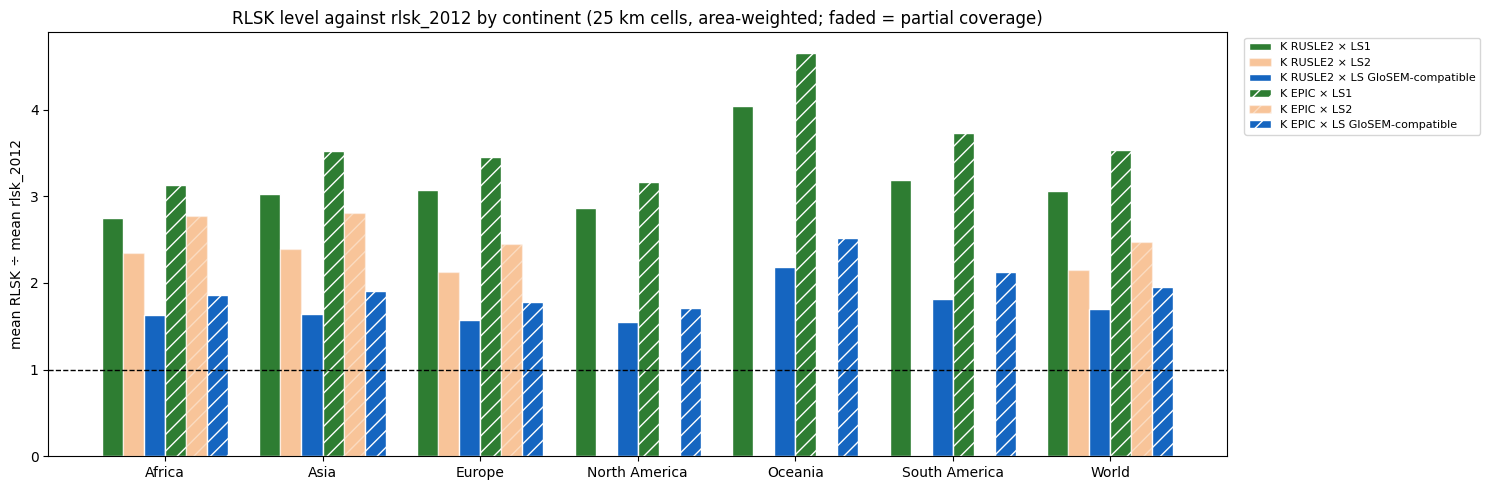

In [13]:
LS_COLOUR = {"LS1": "#2e7d32", "LS2": "#ef6c00", "LS GloSEM-compatible": "#1565c0"}
K_HATCH = {"K RUSLE2": "", "K EPIC": "//"}
regs = CONTINENTS + ["World"]
fig, ax = plt.subplots(figsize=(15, 5))
width = 0.8 / len(VARIANTS)
for i, (k, ls) in enumerate(VARIANTS):
    sub = by_continent[by_continent["variant"] == vname(k, ls)].set_index("region").reindex(regs)
    partial = sub["coverage %"].values < 99
    bars = ax.bar(np.arange(len(regs)) + (i - (len(VARIANTS) - 1) / 2) * width, sub["new ÷ 2012"].values, width,
                  color=LS_COLOUR[ls], hatch=K_HATCH[k], edgecolor="white", label=vname(k, ls))
    for bar, p in zip(bars, partial):
        if p:
            bar.set_alpha(0.4)
ax.axhline(1, color="k", ls="--", lw=1)
ax.set_xticks(np.arange(len(regs)), regs)
ax.set_ylabel("mean RLSK ÷ mean rlsk_2012")
ax.set_title("RLSK level against rlsk_2012 by continent (25 km cells, area-weighted; faded = partial coverage)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()
plt.show()

### 5.4 Which factor drives the gap?
For every 25 km cell, the log ratio splits exactly into factor terms:

$$\log\frac{RLSK_{new}}{RLSK_{2012}} = \log\frac{\bar R_{new}}{R_{G}} + \log\frac{\bar K_{new}}{K_{G}} + \log\frac{\bar{LS}_{new}}{LS_{G}} + \underbrace{\log\frac{RLSK_{new}}{\bar R_{new}\bar K_{new}\bar{LS}_{new}}}_{\text{sub-cell aggregation}}$$

Here $\bar X_{new}$ is the 25 km mean of the new factor and $X_G$ the GloSEM v1.1 factor. Each term is shown as a geometric-mean ratio (area-weighted over cells where all terms are positive), so the terms multiply to the total.

In [14]:
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)

r25_new = read_25(R_25KM_FP)
k25_new = {k: read_25(v[2]) for k, v in K_VARIANTS.items()}
ls25_new = {}
for ls, (_, fp) in LS_VARIANTS.items():
    dst = np.full(G_SHAPE, np.nan)
    with rasterio.open(fp) as s:
        reproject(rasterio.band(s, 1), dst, src_nodata=s.nodata, dst_transform=G_TR, dst_crs=G_CRS,
                  dst_nodata=np.nan, resampling=Resampling.average)
    ls25_new[ls] = dst


def gmean_ratio(log_terms, m):
    return float(2 ** np.average(log_terms[m], weights=G_W[m])) if m.any() else np.nan


rows = []
for (k, ls), a in new25.items():
    terms = {"R": np.log2(r25_new / g["R"]), "K": np.log2(k25_new[k] / g["K"]), "LS": np.log2(ls25_new[ls] / g["LS"]),
             "aggregation": np.log2(a / (r25_new * k25_new[k] * ls25_new[ls]))}
    total = np.log2(a / old)
    with np.errstate(invalid="ignore", divide="ignore"):
        ok = np.isfinite(total) & np.logical_and.reduce([np.isfinite(t) for t in terms.values()])
    for reg, in_reg in regions.items():
        m = ok & in_reg
        row = {"variant": vname(k, ls), "region": reg, "cells": int(m.sum())}
        row.update({f"× {name}": gmean_ratio(t, m) for name, t in terms.items()})
        row["× total"] = gmean_ratio(total, m)
        row["check: product of terms ÷ total"] = np.prod([row[f"× {n}"] for n in terms]) / row["× total"] if m.any() else np.nan
        rows.append(row)
decomp = pd.DataFrame(rows)
decomp.to_csv(OUT / "rlsk_new_vs_2012_factor_decomposition.csv", index=False)

display(decomp[decomp["region"] == "World"].set_index("variant").drop(columns="region").round(3))
display(decomp[decomp["variant"] == vname(*MAIN)].set_index("region").drop(columns="variant").round(3))

,cells,× R,× K,× LS,× aggregation,× total,check: product of terms ÷ total
variant,,,,,,,
K RUSLE2 × LS1,278490,0.946,1.058,2.063,1.004,2.074,1.0
K RUSLE2 × LS2,10550,1.243,1.007,1.966,1.008,2.484,1.0
K RUSLE2 × LS GloSEM-compatible,278490,0.946,1.058,1.330,1.004,1.337,1.0
K EPIC × LS1,278490,0.946,1.193,2.063,1.005,2.337,1.0
K EPIC × LS2,10550,1.243,1.150,1.966,1.009,2.835,1.0
K EPIC × LS GloSEM-compatible,278490,0.946,1.193,1.330,1.004,1.506,1.0


,cells,× R,× K,× LS,× aggregation,× total,check: product of terms ÷ total
region,,,,,,,
Africa,38379,0.991,1.209,1.715,1.002,2.058,1.0
Asia,100680,0.941,0.921,2.351,1.006,2.051,1.0
Europe,30397,1.167,0.996,2.345,1.007,2.744,1.0
North America,58161,0.708,1.026,2.420,1.007,1.770,1.0
Oceania,17260,1.236,1.076,1.242,1.001,1.655,1.0
South America,33256,0.983,1.283,1.947,1.002,2.458,1.0
World,278490,0.946,1.058,2.063,1.004,2.074,1.0


### 5.5 Maps and scatter (main variant)

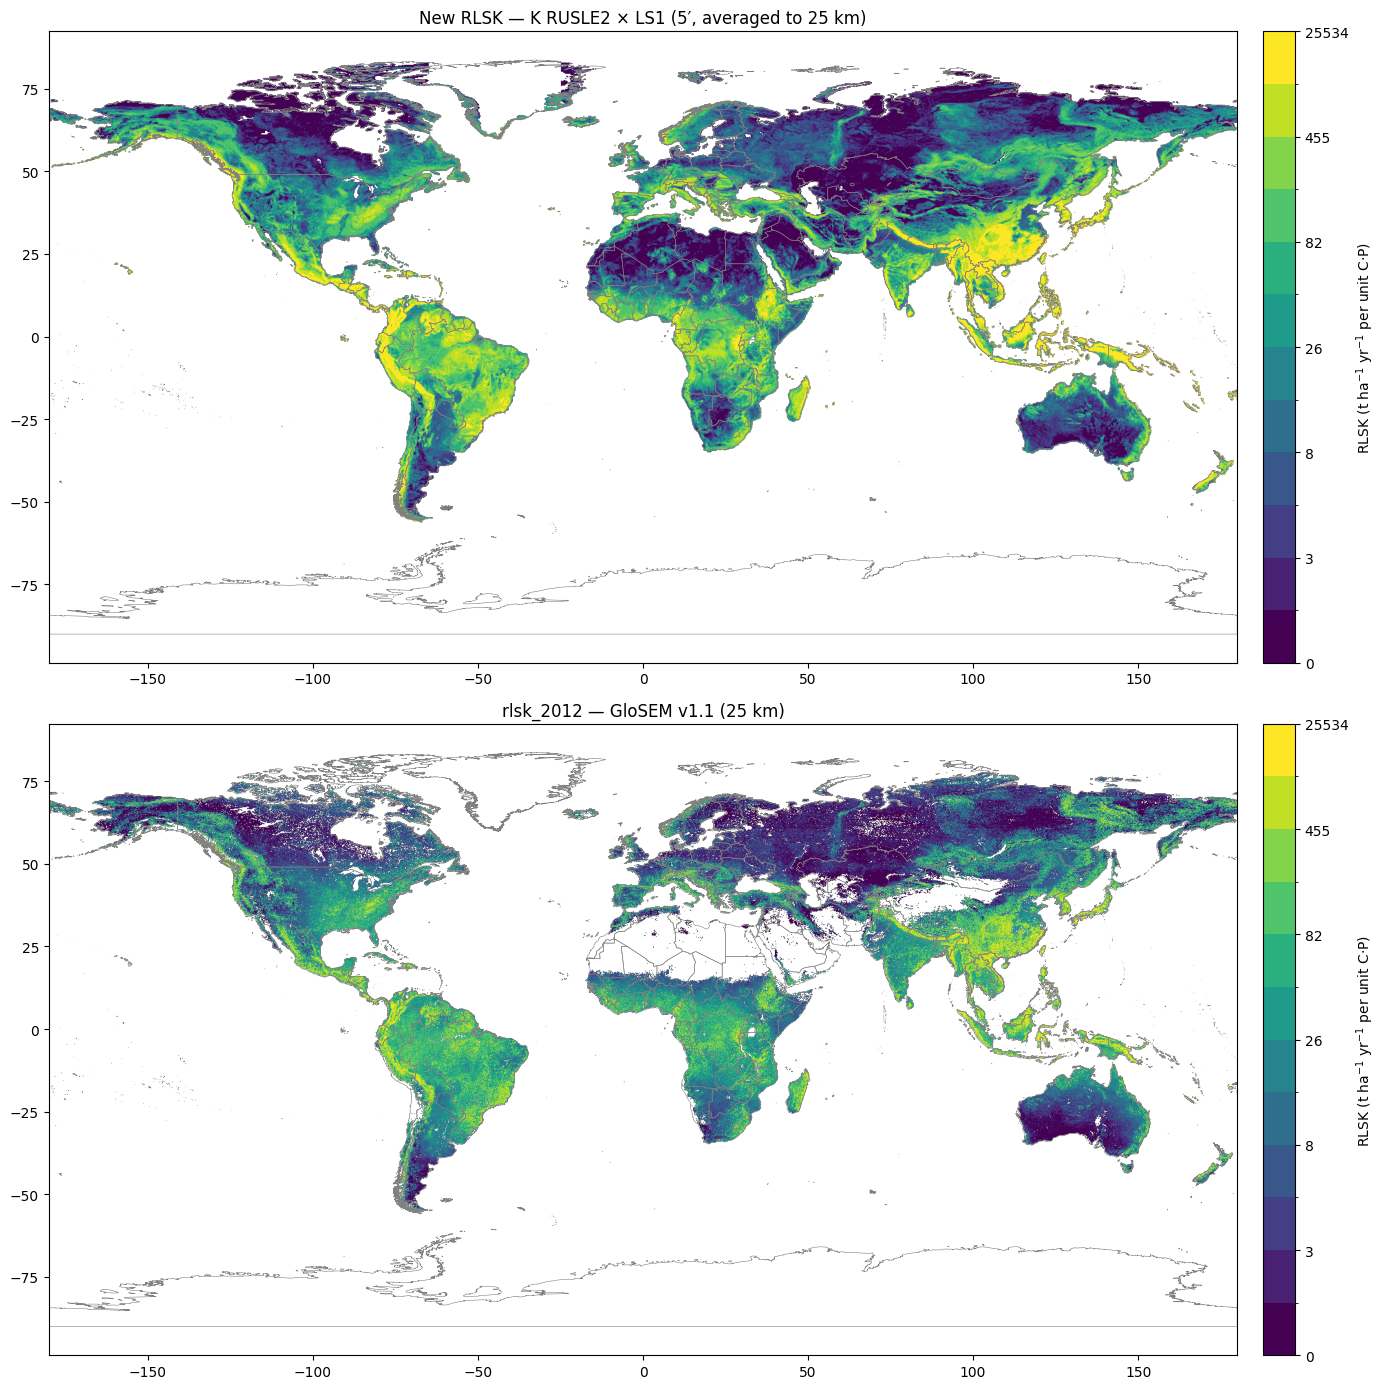

(<Figure size 1400x1400 with 4 Axes>,
 array([[<Axes: title={'center': 'New RLSK — K RUSLE2 × LS1 (5′, averaged to 25 km)'}>],
        [<Axes: title={'center': 'rlsk_2012 — GloSEM v1.1 (25 km)'}>]],
       dtype=object))

In [15]:
mp.plot_n_rasters_on_world_extremes_cutoff(
    [RLSK_NEW_25KM_FP, RLSK_OLD_F32_FP],
    titles=[f"New RLSK — {vname(*MAIN)} (5′, averaged to 25 km)", "rlsk_2012 — GloSEM v1.1 (25 km)"],
    label_title=RLSK_LABEL, perc_cutoff=0,
    quantiles=[0] + [float(np.round(q, 1)) for q in np.percentile(old[old_ok], [10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 99])]
              + [float(max(np.nanmax(new25[MAIN]), np.nanmax(old)))],
    n_cols=1, x_size=14, y_size=7,
)

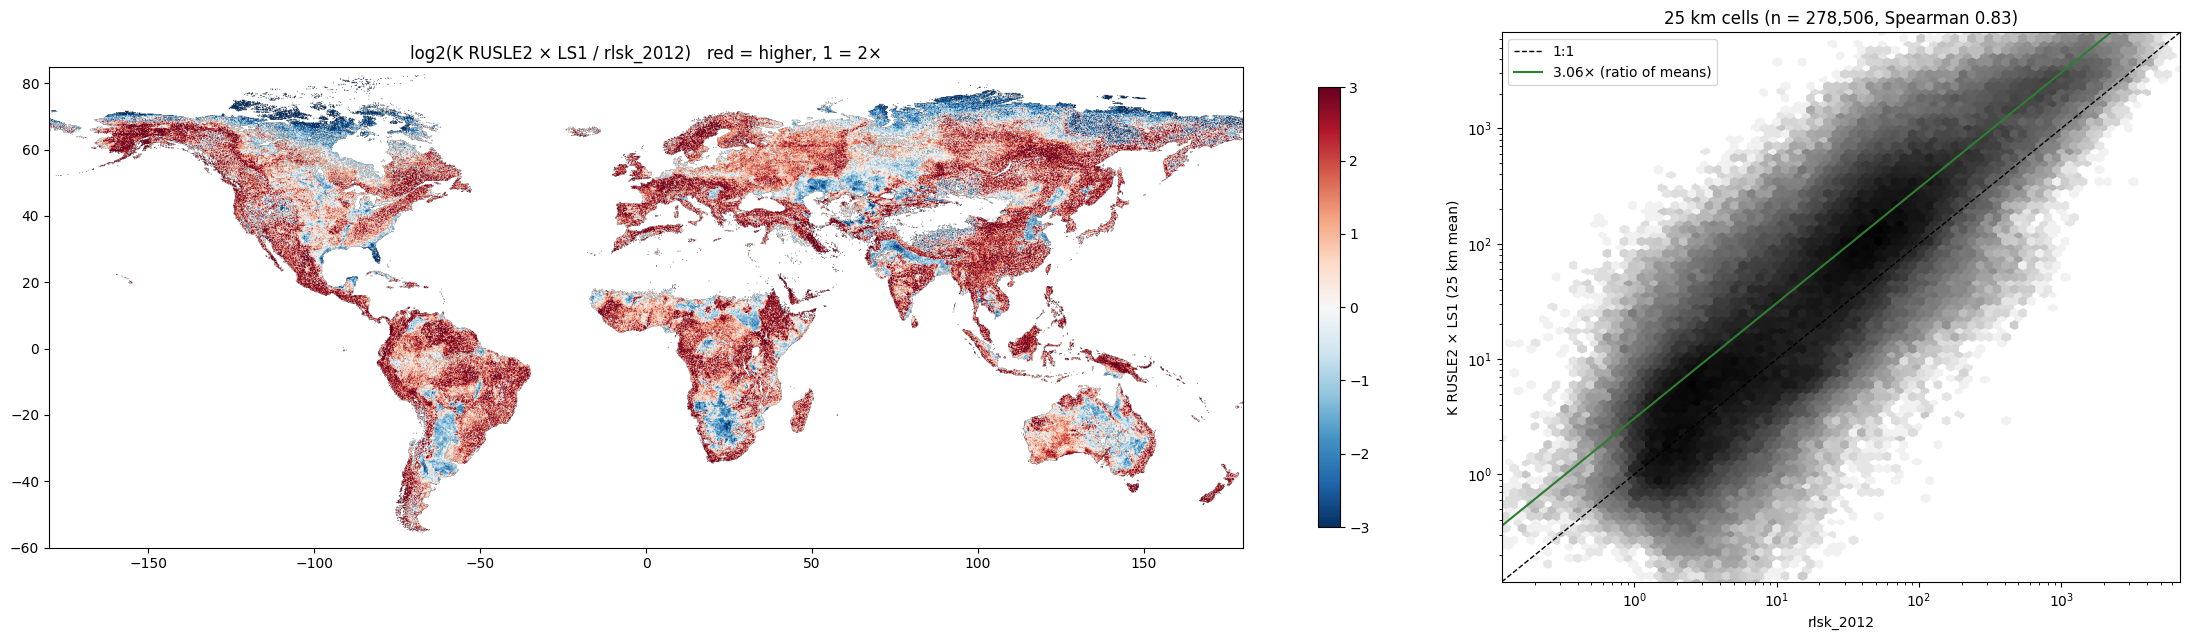

In [16]:
a = new25[MAIN]
c = old_ok & np.isfinite(a)
pos = c & (old > 0) & (a > 0)
ratio = summary[vname(*MAIN)]["new ÷ 2012 (means)"]
g_extent = (G_TR.c, G_TR.c + G_SHAPE[1] * G_TR.a, G_TR.f + G_SHAPE[0] * G_TR.e, G_TR.f)

fig, (ax_m, ax_s) = plt.subplots(1, 2, figsize=(22, 6.5), gridspec_kw=dict(width_ratios=[2.2, 1]))
im = ax_m.imshow(np.where(pos, np.log2(a / old), np.nan), extent=g_extent, cmap="RdBu_r", vmin=-3, vmax=3)
ax_m.set_ylim(-60, 85)
ax_m.set_title(f"log2({vname(*MAIN)} / rlsk_2012)   red = higher, 1 = 2×")
plt.colorbar(im, ax=ax_m, shrink=0.8)

lo, hi = np.percentile(np.concatenate([a[pos], old[pos]]), [0.1, 99.9])
ax_s.hexbin(old[pos], a[pos], gridsize=80, bins="log", xscale="log", yscale="log", mincnt=1, cmap="Greys",
            extent=(np.log10(lo), np.log10(hi), np.log10(lo), np.log10(hi)))
ax_s.plot([lo, hi], [lo, hi], "k--", lw=1, label="1:1")
ax_s.plot([lo, hi], [lo * ratio, hi * ratio], color="#2e7d32", lw=1.5, label=f"{ratio:.2f}× (ratio of means)")
ax_s.set(xlim=(lo, hi), ylim=(lo, hi), xlabel="rlsk_2012", ylabel=f"{vname(*MAIN)} (25 km mean)",
         title=f"25 km cells (n = {pos.sum():,}, Spearman {summary[vname(*MAIN)]['Spearman']:.2f})")
ax_s.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 6. Conclusions (run of 2026-11-25; K floored at 0.004, K EPIC corrected dropped)
**Layer.** `RUSLE/outputs/rusle_RLSK_5m.tif` (K RUSLE2 × LS1, UHTH 5′ grid, 2.16 M cells) is the new main RLSK. Five variants sit next to it as `rusle_RLSK_5m_<k>_<ls>.tif`.
- No cell is negative. 2,943 cells are 0, all where GloREDa R = 0 (no rainfall erosivity), not from K.
- Coverage is the intersection of RK and LS: 143 k cells have LS but no R or K (75% of them north of 62°N, where GloREDa has few data; the rest mainly coasts); 1 k cells have RK but no LS.

**The 30″ R × K step barely matters on average:** multiplying 5′ means instead changes the global mean by 0.01%. 98% of cells change by less than 5%, and the 1st–99th percentile range is 0.95–1.06.

**`rlsk_2012` is exactly R × K × LS of GloSEM v1.1** (max deviation 4e-16), so the factor decomposition is exact.

**Main variant against `rlsk_2012`** (25 km, 99.99% coverage):
- The pattern agrees: Spearman 0.83, Pearson r 0.70 (0.83 on logs).
- The level is about 3× higher: 3.06× by area-weighted means, 1.91× by the median cell, 2.07× by the geometric mean. The new layer has a heavier upper tail (p95 1,619 vs 455).
- By continent: 2.75× (Africa) to 4.0× (Oceania).

**Almost all of the gap comes from LS** (geometric-mean factors, world):

| R | K | LS | sub-cell aggregation | total |
|---|---|---|---|---|
| 0.95× | 1.06× | 2.06× | 1.00× | 2.07× |

R and K roughly cancel by continent. For example, North America has R 0.71× and Europe R 1.17×; Africa and South America have K 1.2–1.3×. LS is 1.7–2.4× everywhere except Oceania (1.24×). This is the Desmet & Govers area-term issue documented in `RUSLE/README.md` (LS Layer, items 6–8).

**Variants (world, ratio of means against `rlsk_2012`):**

| | LS1 | LS GloSEM-compatible | LS2 (only box n30e000, 3.8% coverage) |
|---|---|---|---|
| K RUSLE2 | **3.06** | 1.69 | 2.15 (LS1 on the same cells: 3.21) |
| K EPIC | 3.53 | 1.96 | 2.48 |

- With the GloSEM-compatible LS, the new RLSK is 1.7× `rlsk_2012`, with the same rank agreement (Spearman 0.83).
- LS2 falls between LS1 and the GloSEM-compatible layer on its box. It needs the global LS2 run before it can be judged.
- K EPIC gives about 15% more than K RUSLE2.

**K changes in this run.**
- **K is floored at `K_MIN` = 0.004** t ha h ha⁻¹ MJ⁻¹ mm⁻¹ in `calculate_K_RUSLE_2` and `calculate_K_Epic`, because K = 0 would mean no erosion. The value sits within the published lower bounds: the EU K map minimum (Panagos et al. 2014), the lowest Wischmeier & Smith benchmark soil, the Renard $D_g$ floor (0.0034) and the GloSEM v1.1 minimum (0.0047).
  - In K RUSLE2, 56,456 pixels (0.044%) sit at the floor; the mean is unchanged (0.0273).
  - K EPIC (min 0.0056) never reaches it.
- **K EPIC corrected** (Yang et al. 2024 Eq. 27, $1.8722K-0.05$) is no longer produced. It was negative in 26% of pixels, because our EPIC-K (mean 0.030) is below Yang's (0.040) and the equation crosses 0 at K = 0.0267.
